## Harvard AI Bootcamp

# AI Stock Market Predictor

**Microsoft (MSFT) next-session adjusted closing price with Python and PyTorch.**

This learning project adapts the Harvard AI Bootcamp stock-prediction notebook supplied by Siddharth Vadali. It uses the previous 50 trading sessions of OHLCV data to predict the following session's adjusted close. An LSTM predicts an adjustment to the most recent observed close; a previous-close baseline is evaluated on exactly the same held-out dates.

[GitHub project](https://github.com/SiddV19/AI-projects/blob/main/stock-market-predictor/README.md) · [Original Colab notebook](https://colab.research.google.com/drive/1OG71mQ3pkkOUsqxHZ-SIsXXWK1x9irTk)


## Run this notebook

Choose **Runtime → Restart session and run all** to run every setup cell in order. A CPU works; a GPU is used automatically when available. Missing dependencies are installed from PyPI by the first code cell. Viewers should choose **File → Save a copy in Drive** before editing.

The example uses a fixed Yahoo Finance download interval ending before **2026-11-19** (exclusive), so the latest intended observation is 2026-11-18. Yahoo may revise adjusted prices. Change the dates explicitly for a new experiment. The chronological 80/20 split happens before fitting either scaler. Model settings are fixed before evaluating the test set.

The charts and error metrics describe a one-step-ahead historical test, using previously observed prices at each step. They do not measure trading returns or establish that the model beats the previous-close baseline.


# Step #1 Load the Data

In [1]:
# Install only dependencies missing from the active notebook environment.
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn', 'seaborn': 'seaborn',
    'torch': 'torch', 'yfinance': 'yfinance',
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

import json
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import torch
import torch.nn as nn
import yfinance as yf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
sns.set_theme(style='whitegrid')


In [2]:
symbol = 'MSFT'
stockname = 'Microsoft (MSFT)'
start_date = '2010-01-01'
end_date = '2026-11-19'  # Yahoo Finance's end date is exclusive.

df = yf.download(
    symbol, start=start_date, end=end_date, auto_adjust=True,
    multi_level_index=False, progress=False, threads=False, timeout=30,
)
if df is None or df.empty:
    raise RuntimeError('Yahoo Finance returned no data. Check connectivity and rerun this cell.')

# Normalize a single-ticker response across yfinance versions.
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
required_columns = ['High', 'Low', 'Open', 'Close', 'Volume']
if not set(required_columns).issubset(df.columns) or df.columns.duplicated().any():
    raise ValueError(f'Unexpected Yahoo Finance columns: {df.columns.tolist()}')
df = df[required_columns].apply(pd.to_numeric, errors='coerce').dropna().sort_index()
df = df.loc[~df.index.duplicated(keep='last')]
df.index = pd.to_datetime(df.index).tz_localize(None)
if len(df) < 100 or not np.isfinite(df.to_numpy()).all():
    raise ValueError('Not enough valid observations to create training and test sequences.')
if (df[['High', 'Low', 'Open', 'Close']] <= 0).any().any():
    raise ValueError('Price observations must be positive.')
print(f'{stockname}: {len(df):,} observations, {df.index[0].date()} through {df.index[-1].date()}')


Microsoft (MSFT): 4,245 observations, 2010-01-04 through 2026-11-17


# Step #2 Exploring the Data

In [3]:

df.head()

,High,Low,Open,Close,Volume
Date,,,,,
2010-01-04,23.095629,22.716890,22.739170,22.984236,38409100
2010-01-05,23.095629,22.754021,22.909973,22.991661,49749600
2010-01-06,23.080786,22.664916,22.932260,22.850573,58182400
2010-01-07,22.798587,22.419848,22.746602,22.612930,50559700
2010-01-08,22.932256,22.456976,22.486682,22.768879,51197400


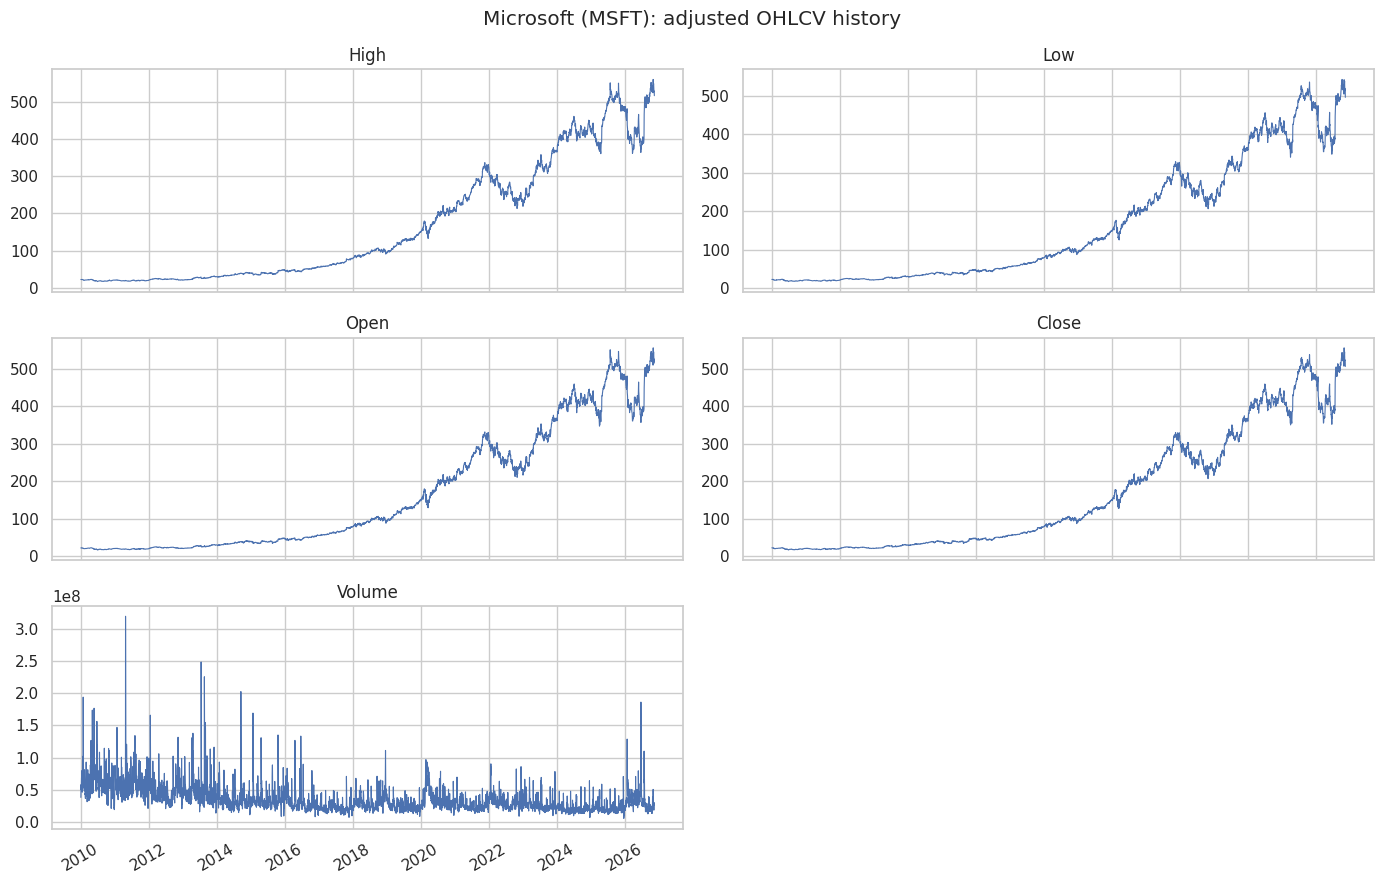

In [4]:
# Show all five features, including volume; hide the unused sixth axis.
ncols = 2
nrows = math.ceil(len(df.columns) / ncols)
fig, axes = plt.subplots(nrows, ncols, sharex=True, figsize=(14, 9))
for ax, column in zip(axes.flat, df.columns):
    ax.plot(df.index, df[column], linewidth=0.8)
    ax.set_title(column)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.tick_params(axis='x', rotation=30)
for ax in list(axes.flat)[len(df.columns):]:
    ax.set_visible(False)
fig.suptitle(f'{stockname}: adjusted OHLCV history')
fig.tight_layout()
plt.show()


# Step #3 Preprocessing and Feature Selection

In [5]:
# Keep observations chronological. Only these five historical features are inputs.
train_df = df.sort_index().copy()
FEATURES = ['High', 'Low', 'Open', 'Close', 'Volume']
print('Feature list:', FEATURES)


Feature list: ['High', 'Low', 'Open', 'Close', 'Volume']


In [6]:
data_filtered = train_df[FEATURES].copy()
data_filtered_ext = data_filtered.copy()
data_filtered.tail()


,High,Low,Open,Close,Volume
Date,,,,,
2026-11-11,534.760010,518.450012,534.239990,521.130005,29076800
2026-11-12,529.659973,520.000000,521.099976,523.000000,18644000
2026-11-13,526.419983,513.820007,519.750000,523.880005,26189200
2026-11-16,527.950012,516.820007,525.090027,517.989990,30218600
2026-11-17,515.640015,496.510010,514.570007,506.239990,27992800


In [7]:
sequence_length = 50
train_data_len = int(len(data_filtered) * 0.8)
if train_data_len <= sequence_length or train_data_len >= len(data_filtered):
    raise ValueError('The split must leave at least one training and one test sequence.')

np_data_unscaled = data_filtered.to_numpy(dtype=np.float64)
close_values = data_filtered[['Close']].to_numpy(dtype=np.float64)

# Fit on the training period ONLY; transform held-out observations without refitting.
scaler = MinMaxScaler().fit(np_data_unscaled[:train_data_len])
scaler_pred = MinMaxScaler().fit(close_values[:train_data_len])
np_data_scaled = scaler.transform(np_data_unscaled)
np_Close_scaled = scaler_pred.transform(close_values)
index_Close = FEATURES.index('Close')
np.testing.assert_allclose(np_data_scaled[:, index_Close], np_Close_scaled[:, 0])
assert scaler.n_samples_seen_ == scaler_pred.n_samples_seen_ == train_data_len

print(f'Training dates: {data_filtered.index[0].date()} to {data_filtered.index[train_data_len - 1].date()}')
print(f'Test dates: {data_filtered.index[train_data_len].date()} to {data_filtered.index[-1].date()}')


Training dates: 2010-01-04 to 2023-06-30
Test dates: 2023-07-03 to 2026-11-17


In [8]:
def partition_dataset(window, features, targets):
    """Each target is the close AFTER the last input day, never an input from that day."""
    if len(features) != len(targets) or len(features) <= window:
        raise ValueError('Features and targets must align and exceed the window length.')
    x = np.stack([features[i - window:i] for i in range(window, len(features))])
    y = np.asarray(targets[window:], dtype=np.float32).reshape(-1, 1)
    return x.astype(np.float32), y

train_data = np_data_scaled[:train_data_len]
test_start = train_data_len - sequence_length
test_data = np_data_scaled[test_start:]
x_train, y_train = partition_dataset(
    sequence_length, train_data, np_Close_scaled[:train_data_len])
x_test, y_test = partition_dataset(
    sequence_length, test_data, np_Close_scaled[test_start:])
test_dates = data_filtered.index[train_data_len:]

assert x_train.shape == (train_data_len - sequence_length, sequence_length, len(FEATURES))
assert x_test.shape == (len(test_dates), sequence_length, len(FEATURES))
assert y_train.shape == (len(x_train), 1) and y_test.shape == (len(x_test), 1)
np.testing.assert_allclose(x_test[0], np_data_scaled[test_start:train_data_len], rtol=1e-5)
np.testing.assert_allclose(
    scaler_pred.inverse_transform(y_test).ravel(), close_values[train_data_len:, 0], rtol=1e-5)
print('Train:', x_train.shape, y_train.shape)
print('Test:', x_test.shape, y_test.shape)


Train: (3346, 50, 5) (3346, 1)
Test: (849, 50, 5) (849, 1)


# Step #4 Model Training

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(min(2, torch.get_num_threads()))
print('Training device:', device)


Training device: cuda


In [10]:
class LSTMModel(nn.Module):
    """Predict a next-close adjustment relative to the last observed close."""
    def __init__(self, input_size, hidden_size, num_layers, output_size, close_index):
        super().__init__()
        self.close_index = close_index
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 5)
        self.fc2 = nn.Linear(5, output_size)
        # Start from the previous-close baseline before learning an adjustment.
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        out, _ = self.lstm(x)  # PyTorch creates zero states on the input's device.
        adjustment = self.fc2(torch.relu(self.fc1(out[:, -1, :])))
        previous_close = x[:, -1, self.close_index:self.close_index + 1]
        return previous_close + adjustment

class TimeSeriesDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.as_tensor(x, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
        if self.x.ndim != 3 or len(self.x) != len(self.y):
            raise ValueError('Expected aligned [samples, time steps, features] inputs and targets.')

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


In [11]:
# These settings are fixed before inspecting the held-out test metrics.
torch.manual_seed(SEED)
input_size = len(FEATURES)
hidden_size = 64
num_layers = 2
output_size = 1
learning_rate = 1e-3
batch_size = 64
epochs = 30

model = LSTMModel(input_size, hidden_size, num_layers, output_size, index_Close).to(device)
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


In [12]:
# Dataset conversion is safe to repeat: NumPy arrays are retained as the source.
train_dataset = TimeSeriesDataset(x_train, y_train)
test_dataset = TimeSeriesDataset(x_test, y_test)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

history = []
for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for x_batch, y_batch in train_dataloader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(x_batch)
        assert outputs.shape == y_batch.shape, (outputs.shape, y_batch.shape)
        loss = criterion(outputs, y_batch)  # Both have shape [batch, 1].
        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite training loss.')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(x_batch)
    epoch_loss = total_loss / len(train_dataset)
    history.append(epoch_loss)
    if epoch == 0 or (epoch + 1) % 5 == 0 or epoch + 1 == epochs:
        print(f'Epoch [{epoch + 1}/{epochs}], Mean training MAE (scaled): {epoch_loss:.6f}')

model.eval()
with torch.no_grad():
    y_pred_scaled = torch.cat([
        model(x_batch.to(device)).cpu() for x_batch, _ in test_dataloader
    ]).numpy()
y_pred = scaler_pred.inverse_transform(y_pred_scaled)
y_test_unscaled = scaler_pred.inverse_transform(test_dataset.y.numpy())
baseline_pred = close_values[train_data_len - 1:-1].copy()
assert y_pred.shape == y_test_unscaled.shape == baseline_pred.shape
assert np.isfinite(y_pred).all()


Epoch [1/30], Mean training MAE (scaled): 0.004026
Epoch [5/30], Mean training MAE (scaled): 0.004009
Epoch [10/30], Mean training MAE (scaled): 0.004001
Epoch [15/30], Mean training MAE (scaled): 0.004007
Epoch [20/30], Mean training MAE (scaled): 0.004007
Epoch [25/30], Mean training MAE (scaled): 0.004003
Epoch [30/30], Mean training MAE (scaled): 0.004003


# Step #5 Evaluate Model Performance

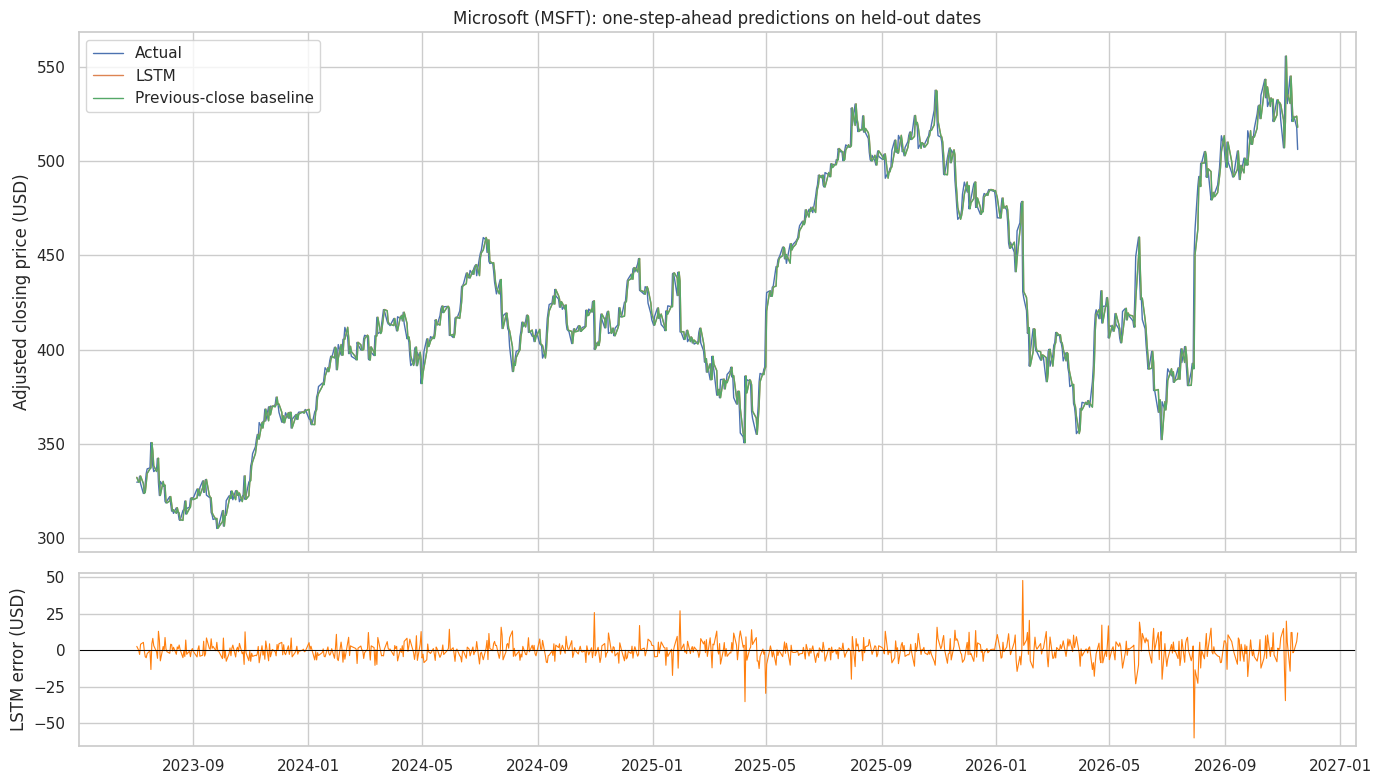

In [13]:
valid = pd.DataFrame({
    'Actual': y_test_unscaled.ravel(),
    'LSTM': y_pred.ravel(),
    'Previous-close baseline': baseline_pred.ravel(),
}, index=test_dates)
valid['Residual'] = valid['LSTM'] - valid['Actual']

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})
valid[['Actual', 'LSTM', 'Previous-close baseline']].plot(ax=axes[0], linewidth=1)
axes[0].set_title(f'{stockname}: one-step-ahead predictions on held-out dates')
axes[0].set_ylabel('Adjusted closing price (USD)')
axes[1].plot(valid.index, valid['Residual'], color='tab:orange', linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].set_ylabel('LSTM error (USD)')
fig.tight_layout()
plt.show()


In [14]:
def error_metrics(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()
    percentage_errors = np.abs((actual - predicted) / actual) * 100
    return {
        'MAE (USD)': float(mean_absolute_error(actual, predicted)),
        'RMSE (USD)': float(np.sqrt(mean_squared_error(actual, predicted))),
        'MAPE (%)': float(np.mean(percentage_errors)),
        'MDAPE (%)': float(np.median(percentage_errors)),
    }

lstm_metrics = error_metrics(y_test_unscaled, y_pred)
baseline_metrics = error_metrics(y_test_unscaled, baseline_pred)
metrics = pd.DataFrame([lstm_metrics, baseline_metrics],
                       index=['LSTM', 'Previous-close baseline'])
print(metrics.round(4).to_string())
mae_improvement_pct = 100 * (1 - lstm_metrics['MAE (USD)'] / baseline_metrics['MAE (USD)'])
if mae_improvement_pct > 0:
    print(f'LSTM test MAE is {mae_improvement_pct:.2f}% lower than the previous-close baseline.')
else:
    print(f'LSTM does not beat the previous-close baseline on test MAE ({mae_improvement_pct:.2f}% improvement).')
print('This is a held-out one-step prediction experiment, not a trading-return backtest.')


                         MAE (USD)  RMSE (USD)  MAPE (%)  MDAPE (%)
LSTM                        4.7550      6.9215    1.1305     0.8236
Previous-close baseline     4.7607      6.9238    1.1318     0.8232
LSTM test MAE is 0.12% lower than the previous-close baseline.
This is a held-out one-step prediction experiment, not a trading-return backtest.


# Step #6 Predict the Next Trading Session

Use the evaluated model and the most recent 50 observed sessions. The model remains trained on the earlier 80% of observations; it is not refitted using the test set. This is an experimental point forecast, without a confidence interval.


In [15]:
last_window = scaler.transform(data_filtered.iloc[-sequence_length:].to_numpy())
X_test_new = torch.as_tensor(last_window[None, :, :], dtype=torch.float32, device=device)
model.eval()
with torch.no_grad():
    next_scaled = model(X_test_new).cpu().numpy()
predicted_price = float(scaler_pred.inverse_transform(next_scaled)[0, 0])
price_today = float(data_filtered['Close'].iloc[-1])
change_percent = (predicted_price - price_today) / price_today * 100
last_observed_date = data_filtered.index[-1].date().isoformat()
assert np.isfinite(predicted_price)
print(f'{stockname} last observed adjusted close ({last_observed_date}): ${price_today:.2f}')
print(f'Experimental next-session adjusted-close prediction: ${predicted_price:.2f} ({change_percent:+.2f}%)')


Microsoft (MSFT) last observed adjusted close (2026-11-17): $506.24
Experimental next-session adjusted-close prediction: $506.34 (+0.02%)


In [16]:
# End-to-end checks and environment details for this executed notebook.
from importlib.metadata import version

assert len(valid) == len(data_filtered) - train_data_len
assert valid.index.equals(test_dates) and valid.index.is_monotonic_increasing
assert scaler.n_samples_seen_ == scaler_pred.n_samples_seen_ == train_data_len
assert np.isfinite(metrics.to_numpy()).all() and np.isfinite(history).all()
assert data_filtered.index[train_data_len - 1] < test_dates[0]
assert next_scaled.shape == (1, 1)
np.testing.assert_allclose(y_test_unscaled.ravel(), close_values[train_data_len:, 0], rtol=1e-5)

run_summary = {
    'ticker': symbol,
    'last_observed_date': last_observed_date,
    'observations': len(data_filtered),
    'training_observations': train_data_len,
    'training_sequences': len(x_train),
    'test_sequences': len(x_test),
    'test_start': test_dates[0].date().isoformat(),
    'test_end': test_dates[-1].date().isoformat(),
    'window': sequence_length,
    'epochs': epochs,
    'seed': SEED,
    'device': str(device),
    'lstm_metrics': lstm_metrics,
    'baseline_metrics': baseline_metrics,
    'mae_improvement_pct': float(mae_improvement_pct),
    'next_session_prediction': predicted_price,
    'packages': {name: version(name) for name in packages.values()},
    'checks_passed': True,
}
print('VALIDATION PASSED: target shapes, date alignment, training-only scaling, and finite predictions.')
print(json.dumps(run_summary, indent=2))


VALIDATION PASSED: target shapes, date alignment, training-only scaling, and finite predictions.
{
  "ticker": "MSFT",
  "last_observed_date": "2026-11-17",
  "observations": 4245,
  "training_observations": 3396,
  "training_sequences": 3346,
  "test_sequences": 849,
  "test_start": "2023-07-03",
  "test_end": "2026-11-17",
  "window": 50,
  "epochs": 30,
  "seed": 42,
  "device": "cuda",
  "lstm_metrics": {
    "MAE (USD)": 4.755023002624512,
    "RMSE (USD)": 6.921469648560721,
    "MAPE (%)": 1.130462884902954,
    "MDAPE (%)": 0.8235989212989807
  },
  "baseline_metrics": {
    "MAE (USD)": 4.760743337750294,
    "RMSE (USD)": 6.923769296779968,
    "MAPE (%)": 1.1317578038243206,
    "MDAPE (%)": 0.8232287966625716
  },
  "mae_improvement_pct": 0.12015634366219219,
  "next_session_prediction": 506.34381103515625,
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "scikit-learn": "1.6.1",
    "seaborn": "0.13.2",
    "torch": "2.14.1+cu130